# ACNE04 fold audit — self-contained

Embeds the images **and** runs the repaired analysis in one go. No dependency on files from any earlier session.

**Settings:** Accelerator → GPU, Internet → On. Without internet it falls back to a weight-free descriptor automatically.

### What changed from the first attempt

| Problem | Fix |
|---|---|
| One group swallowed 441 images (30% of the data) | sweep thresholds, reject any that produces a group above 1% of the data |
| Only 5 of 10 folds parsed | discover every annotation file instead of assuming a filename pattern |
| A single number implied false precision | report a curve, plus leakage with the biggest group removed |

It also reports **exact duplicates** separately. Those need no threshold, so they're unarguable — and it flags any duplicate pair whose filenames carry *different grades*, which would be a labelling inconsistency worth its own paragraph.

## 1. Config

In [1]:
from __future__ import annotations

import csv, json, random, re
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np

# --- edit ------------------------------------------------------------------
ROOT = "/kaggle/input/datasets/atkiyaanisa/acne04/acne04"
OUT = "fold_audit_out"

EMBEDDER = "cnn"          # "cnn" or "tiles"; cnn falls back to tiles on failure
PAIR_FLOOR = 0.90         # pairs below this are never written or swept
MAX_GROUP_FRAC = 0.01     # a group larger than this share of the data is implausible
DUP_THRESHOLD = 0.9999    # at or above this, treat as the same photograph
N_PAIRS_TO_RENDER = 24
BATCH = 64
SEEDS = 20
# ---------------------------------------------------------------------------

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp"}
GRADE_RE = re.compile(r"levle(\d+)_", re.I)


def collect_images(root):
    out = {}
    for p in root.rglob("*"):
        if p.suffix.lower() in IMAGE_EXTS and p.is_file():
            out.setdefault(p.name, p)
    return out

## 2. Fold discovery

In [2]:
def discover_fold_files(root: Path):
    """
    List every annotation text file with its row count, then group them into
    splits by any trailing integer in the name. The first run hard-coded the
    NNEW_(test|trainval)_k pattern and found only five folds, while the Week-1
    audit counted 1457 x 10 rows. Discover instead of assuming.
    """
    info = []
    for p in sorted(root.rglob("*.txt")):
        names = set()
        for line in p.read_text(errors="replace").splitlines():
            tok = next((t for t in line.split()
                        if Path(t).suffix.lower() in IMAGE_EXTS), None)
            if tok:
                names.add(Path(tok).name)
        if names:
            info.append({"path": p, "rel": p.relative_to(root).as_posix(),
                         "n": len(names), "names": names})
    return info


def build_folds(info, n_images):
    """
    Pair each small file (a test split) with the large file sharing its index.
    Returns {label: {"test": set, "trainval": set}}.
    """
    by_idx = defaultdict(list)
    for f in info:
        m = re.search(r"(\d+)(?=\D*$)", Path(f["rel"]).stem)
        idx = m.group(1) if m else "?"
        stem = Path(f["rel"]).stem
        kind = "test" if f["n"] < n_images / 2 else "trainval"
        by_idx[(stem[:stem.rfind(idx)] if idx in stem else stem, idx)].append((kind, f))

    folds = {}
    groups = defaultdict(dict)
    for (prefix, idx), items in by_idx.items():
        for kind, f in items:
            groups[idx].setdefault(kind, set()).update(f["names"])
    for idx, d in groups.items():
        if "test" in d and "trainval" in d:
            folds[idx] = {"test": d["test"], "trainval": d["trainval"]}
    return folds

## 3. Embedders

In [3]:
def embed_tiles(paths, size=64, grid=4, bins=8):
    """
    Weight-free descriptor: per-tile RGB histograms plus a downscaled greyscale
    thumbnail. Captures colour layout and coarse structure, which is what makes
    two photographs of the same face in the same session look alike.

    Not an identity model. Good for near-duplicates, weaker across sessions.
    """
    from PIL import Image

    feats = []
    for p in paths:
        try:
            im = Image.open(p).convert("RGB").resize((size, size), Image.BILINEAR)
        except Exception:
            feats.append(np.zeros(grid * grid * 3 * bins + (size // 4) ** 2, dtype=np.float32))
            continue
        a = np.asarray(im, dtype=np.float32) / 255.0
        step = size // grid
        parts = []
        for gy in range(grid):
            for gx in range(grid):
                tile = a[gy * step:(gy + 1) * step, gx * step:(gx + 1) * step]
                for ch in range(3):
                    h, _ = np.histogram(tile[:, :, ch], bins=bins, range=(0.0, 1.0))
                    parts.append(h.astype(np.float32))
        grey = np.asarray(im.convert("L").resize((size // 4, size // 4), Image.BILINEAR),
                          dtype=np.float32) / 255.0
        parts.append(grey.ravel() * bins)      # comparable scale to the histograms
        feats.append(np.concatenate(parts))
    return np.vstack(feats)


def embed_cnn(paths, batch=BATCH):
    """torchvision ResNet50 penultimate features. Raises if torch is missing."""
    import torch
    import torchvision
    from PIL import Image

    dev = "cuda" if torch.cuda.is_available() else "cpu"
    try:
        w = torchvision.models.ResNet50_Weights.IMAGENET1K_V2
        model = torchvision.models.resnet50(weights=w)
        tf = w.transforms()
    except Exception as e:
        raise RuntimeError(f"could not load pretrained weights ({e}). "
                           "Enable internet in the notebook settings, attach a "
                           "weights dataset, or set EMBEDDER='tiles'.") from e

    model.fc = torch.nn.Identity()
    model.eval().to(dev)

    feats = []
    with torch.no_grad():
        for i in range(0, len(paths), batch):
            ims = []
            for p in paths[i:i + batch]:
                try:
                    ims.append(tf(Image.open(p).convert("RGB")))
                except Exception:
                    ims.append(torch.zeros(3, 224, 224))
            feats.append(model(torch.stack(ims).to(dev)).cpu().numpy())
            print(f"    embedded {min(i + batch, len(paths))}/{len(paths)}", end="\r")
    print()
    return np.vstack(feats).astype(np.float32)


def l2_normalise(x):
    n = np.linalg.norm(x, axis=1, keepdims=True)
    n[n == 0] = 1.0
    return x / n

## 4. Grouping and leakage

In [4]:
class Union:
    def __init__(self, items):
        self.p = {i: i for i in items}

    def find(self, a):
        while self.p[a] != a:
            self.p[a] = self.p[self.p[a]]
            a = self.p[a]
        return a

    def union(self, a, b):
        ra, rb = self.find(a), self.find(b)
        if ra != rb:
            self.p[rb] = ra


def group_at(names, pairs, thr):
    u = Union(names)
    used = 0
    for a, b, v in pairs:
        if v >= thr:
            u.union(a, b)
            used += 1
    return {n: u.find(n) for n in names}, used


def grade_of(name):
    m = GRADE_RE.match(name)
    return int(m.group(1)) if m else None


def leakage(folds, group_of, exclude=frozenset()):
    rates = []
    for k in sorted(folds):
        test = [n for n in folds[k]["test"] if n in group_of and n not in exclude]
        tv = [n for n in folds[k]["trainval"] if n in group_of and n not in exclude]
        if not test or not tv:
            continue
        tvg = {group_of[n] for n in tv}
        rates.append(sum(1 for n in test if group_of[n] in tvg) / len(test))
    return (sum(rates) / len(rates), rates) if rates else (float("nan"), [])


def random_leakage(names, group_of, exclude=frozenset(), seeds=SEEDS, frac=0.2):
    pool = [n for n in sorted(names) if n not in exclude]
    out = []
    for s in range(seeds):
        ns = list(pool)
        random.Random(s).shuffle(ns)
        k = int(len(ns) * frac)
        test, train = ns[:k], set(ns[k:])
        tg = {group_of[n] for n in train}
        out.append(sum(1 for n in test if group_of[n] in tg) / max(1, len(test)))
    return sum(out) / len(out)

## 5. Run

In [5]:
def main():
    root, out = Path(ROOT), Path(OUT)
    out.mkdir(parents=True, exist_ok=True)

    print("=" * 74)
    print("ACNE04 FOLD AUDIT - self-contained")
    print("=" * 74)

    # ---- folds -----------------------------------------------------------
    info = discover_fold_files(root)
    print(f"  annotation text files found: {len(info)}")
    for f in info:
        print(f"    {f['n']:>6} images  {f['rel']}")

    all_names = set()
    for f in info:
        all_names |= f["names"]
    assert all_names, "no annotation files found - check ROOT"

    imgs = collect_images(root)
    names = sorted(n for n in all_names if n in imgs)
    paths = [imgs[n] for n in names]
    print(f"\n  images referenced and present: {len(names)}")

    folds = build_folds(info, len(names))
    print(f"  folds reconstructed: {len(folds)} -> {sorted(folds)}")
    for k in sorted(folds):
        print(f"    fold {k}: test={len(folds[k]['test'])} trainval={len(folds[k]['trainval'])}")
    assert folds, "could not reconstruct any fold"

    # ---- embed -----------------------------------------------------------
    print("\n  embedding ...")
    used = EMBEDDER
    if EMBEDDER == "cnn":
        try:
            X = embed_cnn(paths)
        except Exception as e:
            print(f"    CNN embedder unavailable: {e}")
            print("    falling back to the weight-free tile descriptor")
            used, X = "tiles", embed_tiles(paths)
    else:
        X = embed_tiles(paths)
    X = l2_normalise(X.astype(np.float32))
    print(f"    embedder={used}  shape={X.shape}")

    sim = X @ X.T
    np.fill_diagonal(sim, -1.0)
    iu = np.triu_indices(len(names), k=1)
    vals = sim[iu]
    keep = vals >= PAIR_FLOOR
    order = np.argsort(-vals[keep])
    pairs = [(names[int(a)], names[int(b)], float(v)) for a, b, v in
             zip(iu[0][keep][order], iu[1][keep][order], vals[keep][order])]
    idx_of = {n: i for i, n in enumerate(names)}

    print(f"\n  similarity: min={vals.min():.3f} median={np.median(vals):.3f} "
          f"p99={np.percentile(vals, 99):.3f} max={vals.max():.3f}")
    print(f"  pairs at or above the {PAIR_FLOOR} floor: {len(pairs)}")

    with (out / "pairs.csv").open("w", newline="") as fh:
        w = csv.writer(fh)
        w.writerow(["image_a", "image_b", "similarity"])
        for a, b, v in pairs:
            w.writerow([a, b, f"{v:.6f}"])

    # ---- duplicates ------------------------------------------------------
    print("\n" + "-" * 74)
    print("EXACT AND NEAR-EXACT DUPLICATES  (threshold-free)")
    print("-" * 74)
    dups = [(a, b, v) for a, b, v in pairs if v >= DUP_THRESHOLD]
    for cut in (0.9999, 0.999, 0.995, 0.99):
        print(f"    pairs >= {cut:<7}: {sum(1 for _, _, v in pairs if v >= cut)}")

    mismatch = [(a, b, v) for a, b, v in dups
                if grade_of(a) is not None and grade_of(b) is not None
                and grade_of(a) != grade_of(b)]
    print(f"\n  duplicate pairs whose filenames carry DIFFERENT grades: {len(mismatch)}")
    if mismatch:
        print("  If these are the same photograph with two different severity labels,")
        print("  that is a labelling inconsistency and a finding in its own right.")
        print("  Verify visually before claiming it.")
        for a, b, v in mismatch[:15]:
            print(f"    {v:.6f}  {a} (grade {grade_of(a)})   {b} (grade {grade_of(b)})")

    dgroups, _ = group_at(names, dups, DUP_THRESHOLD)
    dsizes = Counter(Counter(dgroups.values()).values())
    dup_mean, _ = leakage(folds, dgroups)
    print(f"\n  grouping at the duplicate threshold only:")
    print(f"    groups {len(set(dgroups.values()))}, sizes {dict(sorted(dsizes.items()))}")
    print(f"    official-fold leak rate from duplicates alone: {dup_mean:.1%}")

    # ---- sweep -----------------------------------------------------------
    print("\n" + "-" * 74)
    print("THRESHOLD SWEEP")
    print("-" * 74)
    cap = max(2, int(len(names) * MAX_GROUP_FRAC))
    print(f"  plausibility cap: no group may exceed {cap} images\n")
    print(f"  {'thr':>7} {'pairs':>7} {'groups':>7} {'maxgrp':>7} "
          f"{'official':>9} {'random':>8} {'excl-big':>9}  flag")

    sweep = []
    for thr in [0.90, 0.92, 0.94, 0.95, 0.96, 0.97, 0.98, 0.99, 0.995, 0.999, 0.9999]:
        if thr < PAIR_FLOOR:
            continue
        g, usedp = group_at(names, pairs, thr)
        comp = Counter(g.values())
        maxg = max(comp.values())
        big = {n for n in names if comp[g[n]] == maxg} if maxg > cap else set()
        off, _ = leakage(folds, g)
        rnd = random_leakage(names, g)
        exc, _ = leakage(folds, g, exclude=big)
        ok = maxg <= cap
        sweep.append({"thr": thr, "pairs": usedp, "groups": len(comp), "max_group": maxg,
                      "official": off, "random": rnd, "excl_big": exc, "plausible": ok})
        print(f"  {thr:>7.4f} {usedp:>7} {len(comp):>7} {maxg:>7} "
              f"{off:>8.1%} {rnd:>7.1%} {exc:>8.1%}  {'ok' if ok else 'CHAINED'}")

    # ---- reading ---------------------------------------------------------
    print("\n" + "=" * 74)
    print("READING")
    print("=" * 74)
    good = [s for s in sweep if s["plausible"]]
    chosen = None
    if not good:
        print("  No threshold gives plausible group sizes. The embedding is not")
        print("  discriminative enough for identity here. Restrict the claim to")
        print("  exact duplicates, or report a range rather than a point estimate.")
    else:
        chosen = min(good, key=lambda s: s["thr"])
        print(f"  Lowest plausible threshold: {chosen['thr']:.4f}")
        print(f"    groups {chosen['groups']}, largest {chosen['max_group']}")
        print(f"    official folds {chosen['official']:.1%}  vs  random {chosen['random']:.1%}")
        if abs(chosen["official"] - chosen["random"]) < 0.03:
            print("\n  Official and random are within 3 points, so the distributed folds")
            print("  look like a random split at image level - not subject-aware.")
            print("  State it as 'no evidence of subject-aware splitting', not as a")
            print("  specific leak percentage.")
        else:
            print("\n  Official and random differ, so fold construction is doing")
            print("  something. Report both numbers side by side.")
    print("\n  Report the SWEEP, not one number. ACNE04 records no subject identity,")
    print("  so every grouping is an estimate and the leak rate inherits that.")

    thr_g = chosen["thr"] if chosen else DUP_THRESHOLD
    gsel, _ = group_at(names, pairs, thr_g)
    with (out / "groups.csv").open("w", newline="") as fh:
        w = csv.writer(fh)
        w.writerow(["image", "subject_group"])
        for n in names:
            w.writerow([n, gsel[n]])

    (out / "fold_audit.json").write_text(json.dumps({
        "embedder": used, "n_images": len(names), "n_folds": len(folds),
        "fold_files": [{"rel": f["rel"], "n": f["n"]} for f in info],
        "pair_floor": PAIR_FLOOR, "n_pairs": len(pairs),
        "dup_threshold": DUP_THRESHOLD, "n_dup_pairs": len(dups),
        "n_dup_grade_mismatch": len(mismatch),
        "dup_grade_mismatch_examples": [[a, b, v] for a, b, v in mismatch[:50]],
        "dup_only_leak_rate": dup_mean,
        "sweep": sweep, "chosen_threshold": thr_g,
    }, indent=2))
    print(f"\n  wrote {out/'pairs.csv'}, {out/'groups.csv'}, {out/'fold_audit.json'}")
    print(f"  groups.csv uses threshold {thr_g:.4f}")

    # ---- render ----------------------------------------------------------
    try:
        import matplotlib
        matplotlib.use("Agg")
        import matplotlib.pyplot as plt
        from PIL import Image
        k = min(N_PAIRS_TO_RENDER, len(pairs))
        if k:
            fig, axes = plt.subplots(k, 2, figsize=(4, 2 * k))
            axes = np.atleast_2d(axes)
            for i, (a, b, v) in enumerate(pairs[:k]):
                for j, nm in enumerate((a, b)):
                    axes[i, j].imshow(Image.open(paths[idx_of[nm]]).convert("RGB"))
                    axes[i, j].axis("off")
                axes[i, 0].set_title(f"{a}  sim={v:.4f}", fontsize=7, loc="left")
                axes[i, 1].set_title(b, fontsize=7, loc="left")
            plt.tight_layout()
            fig.savefig(out / "top_pairs.png", dpi=90)
            print(f"  wrote {out/'top_pairs.png'} - LOOK AT IT before quoting a number")
    except Exception as e:
        print(f"  (pair rendering skipped: {e})")
    return 0

_ = main()

ACNE04 FOLD AUDIT - self-contained
  annotation text files found: 20
       292 images  Classification/Classification/NNEW_test_0.txt
       292 images  Classification/Classification/NNEW_test_1.txt
       292 images  Classification/Classification/NNEW_test_2.txt
       292 images  Classification/Classification/NNEW_test_3.txt
       292 images  Classification/Classification/NNEW_test_4.txt
      1165 images  Classification/Classification/NNEW_trainval_0.txt
      1165 images  Classification/Classification/NNEW_trainval_1.txt
      1165 images  Classification/Classification/NNEW_trainval_2.txt
      1165 images  Classification/Classification/NNEW_trainval_3.txt
      1165 images  Classification/Classification/NNEW_trainval_4.txt
       292 images  Detection/Detection/VOC2007/ImageSets/Main/NNEW_test_0.txt
       292 images  Detection/Detection/VOC2007/ImageSets/Main/NNEW_test_1.txt
       292 images  Detection/Detection/VOC2007/ImageSets/Main/NNEW_test_2.txt
       292 images  Detectio

100%|██████████| 97.8M/97.8M [00:00<00:00, 241MB/s]


    embedded 1457/1457
    embedder=cnn  shape=(1457, 2048)

  similarity: min=0.048 median=0.732 p99=0.907 max=1.000
  pairs at or above the 0.9 floor: 16834

--------------------------------------------------------------------------
EXACT AND NEAR-EXACT DUPLICATES  (threshold-free)
--------------------------------------------------------------------------
    pairs >= 0.9999 : 38
    pairs >= 0.999  : 38
    pairs >= 0.995  : 38
    pairs >= 0.99   : 38

  duplicate pairs whose filenames carry DIFFERENT grades: 9
  If these are the same photograph with two different severity labels,
  that is a labelling inconsistency and a finding in its own right.
  Verify visually before claiming it.
    1.000000  levle0_185.jpg (grade 0)   levle1_286.jpg (grade 1)
    1.000000  levle1_23.jpg (grade 1)   levle2_153.jpg (grade 2)
    1.000000  levle1_16.jpg (grade 1)   levle2_150.jpg (grade 2)
    1.000000  levle1_131.jpg (grade 1)   levle2_128.jpg (grade 2)
    1.000000  levle0_120.jpg (grade 0)  

## 6. Look at the pairs

Don't skip this. The numbers above are only as good as the grouping behind them.

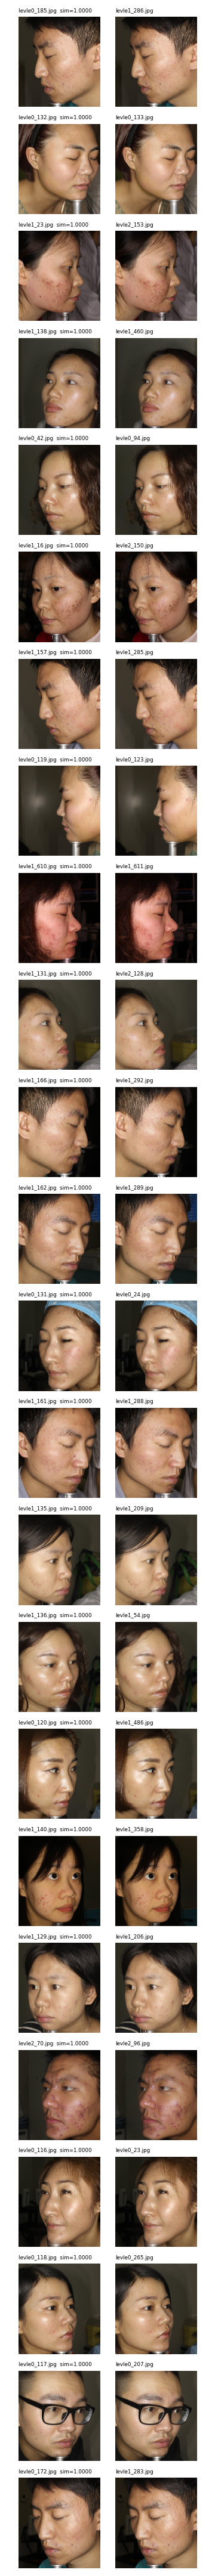

In [6]:
from IPython.display import Image as IPImage, display
from pathlib import Path

p = Path(OUT) / "top_pairs.png"
if p.exists():
    display(IPImage(filename=str(p)))
else:
    print("no top_pairs.png")